<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [FRED and ALFRED](https://github.com/Query-farm/vgi-fred)

Economic observations, historical vintages, revision intervals and discovery metadata.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-fred/blob/main/notebooks/01_reconstruct_gdp_vintages.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-fred/blob/main/notebooks/README.md)


## 01 · What GDP history could an analyst actually have known?

A current time series can contain revisions published long after the measured quarter.
This walkthrough compares a dated ALFRED snapshot with a fixed later reference,
then asks how those revisions change quarter-to-quarter growth.

**Every value here is synthetic.** A small loopback HTTP fixture supplies FRED-shaped
responses to the real, published Python worker through Haybarn and VGI. The GDP
identifier selects this exercise, not official US GDP. No API key or live FRED call
is needed. The eight quarters run from 2019 Q1 through 2020 Q4; levels are toy billions
of US dollars at a seasonally adjusted annual rate. A deliberately missing 2020 Q2
tests whether analysis preserves absence instead of substituting zero.

An observation date names the measured quarter; real-time dates describe when a
version was known. All boundaries below are inclusive calendar dates, not intraday
release timestamps. The fixed reference date is 2021-03-31; it is not today's truth.

### Choose a knowledge date

Choose the knowledge date, then restart and run all. AS_OF accepts ISO dates from
2019-04-30 through 2021-03-31. The measured window and later reference remain fixed,
so changing this parameter cannot silently change the benchmark.

In [1]:
AS_OF = "2020-05-01"

### Run this notebook

Read saved results on GitHub, or choose **Open in Colab** and Run All. The compact setup
installs only the shared base tools and preserves compatible preloaded data/plotting
libraries. Packages, verified companions, the VGI extension and released Git worker
need initial internet access; analytical retrieval then uses only an ephemeral
`127.0.0.1` fixture. uv manages the worker's separate Python 3.13+ environment.

A fresh preloaded Python 3.12 notebook-only run checks this installation path;
actual hosted Colab has not been tested. No checkout, real API key or live account
is needed. The reader can configure official FRED separately using the root README;
these examples never silently switch to a real endpoint.

In [2]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.28":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.28"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.28":
    raise RuntimeError("Install shared tools v0.3.28, then restart and run all.")

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from vgi_notebooks.bootstrap import prepare
from vgi_notebooks.presentation import finish, prose, theme
from vgi_notebooks.session import connect

prepare("fred")
%matplotlib inline
theme()
session = connect(globals())
con = session.connection

from fixture_api import Fixture

fixture = Fixture(AS_OF)
source = "Synthetic GDP fixture · released FRED v0.1.0 via VGI · reference 2021-03-31"

### Attach the release with a temporary fixture credential

The literal Git-tag launcher installs public release **v0.1.0** in a separate environment.
The shared connection verifies an empty temporary SQL-secret directory before ATTACH
and disables persistent secrets. The helper clears inherited FRED key/endpoint settings
for the worker child and routes requests only to the loopback fixture. Its public
all-zero fake key is temporary, never a real credential. Cleanup drops the secret,
checks the empty inventory, closes the connection/server and restores the environment.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'fred' (TYPE vgi,
 LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-fred@v0.1.0 vgi-fred-worker');
CREATE TEMPORARY SECRET fred_fixture
 (TYPE fred_api, API_KEY '00000000000000000000000000000000');
SELECT name, persistent, storage FROM duckdb_secrets();

,name,persistent,storage
0,fred_fixture,False,memory


In [5]:
assert con.execute("SELECT name, persistent, storage FROM duckdb_secrets()").fetchall() == [
    ("fred_fixture", False, "memory")
]

### Establish units and source contract

First establish the source contract. Metadata supplies units and frequency; function
discovery distinguishes the historical snapshot from the revision-interval scan.
Every API-backed call is materialized once before display, preventing JupySQL's
DataFrame capture from issuing the request twice.

In [6]:
%%sql
CREATE TABLE series_info AS
SELECT * FROM fred.main.series('GDP', realtime_start := '2021-03-31', realtime_end := '2021-03-31');
SELECT id, title, frequency, units, seasonal_adjustment, notes FROM series_info;
SELECT function_name FROM duckdb_functions()
WHERE database_name = 'fred' AND function_name IN ('alfred_observations', 'alfred_revisions')
ORDER BY function_name;

,function_name
0,alfred_observations
1,alfred_revisions


### Keep the revision history separate from snapshots

Retrieve the complete revision history through the reference date and two explicit
snapshots over the same eight quarters. Page size five forces real pagination.
Snapshot validity dates are clipped to their requested knowledge date, so the full
history is needed to explain which release supplied each value.

In [7]:
%%sql
CREATE TABLE revision_history AS
SELECT * FROM fred.main.alfred_revisions('GDP',
    observation_start := '2019-01-01', observation_end := '2020-10-01',
    realtime_end := '2021-03-31', page_size := 5);
CREATE TABLE selected_snapshot AS
SELECT * FROM fred.main.alfred_observations('GDP', '{{ AS_OF }}',
    observation_start := '2019-01-01', observation_end := '2020-10-01', page_size := 5);
CREATE TABLE reference_snapshot AS
SELECT * FROM fred.main.alfred_observations('GDP', '2021-03-31',
    observation_start := '2019-01-01', observation_end := '2020-10-01', page_size := 5);
SELECT date AS measured_quarter, value AS level_usd_bn, value_text,
       realtime_start AS known_from, realtime_end AS known_through
FROM revision_history WHERE date = DATE '2020-01-01' ORDER BY realtime_start;

,measured_quarter,level_usd_bn,value_text,known_from,known_through
0,2020-01-01,90.0,90.00,2020-04-30,2020-05-27
1,2020-01-01,91.0,91.00,2020-05-28,2020-06-24
2,2020-01-01,92.0,92.00,2020-06-25,2021-03-31


### Retain unavailable and explicitly missing quarters

Build a calendar spine before joining snapshots. An absent selected row means
the quarter was not yet released; a present row with a NULL value means the source
explicitly reported missing data. The later reference can also be missing.
Revisions are differences in level units, not percentage growth.

In [8]:
%%sql
CREATE TABLE comparison AS
WITH quarters AS (
    SELECT CAST(d AS DATE) AS quarter
    FROM generate_series(DATE '2019-01-01', DATE '2020-10-01', INTERVAL '3 months') AS t(d)
), first_release AS (
    SELECT date, value, realtime_start FROM revision_history
    QUALIFY row_number() OVER (PARTITION BY date ORDER BY realtime_start) = 1
)
SELECT q.quarter, strftime(q.quarter, '%Y') || ' Q' || quarter(q.quarter) AS period,
    s.value AS selected_usd_bn, r.value AS reference_usd_bn, f.value AS first_usd_bn,
    CASE WHEN s.date IS NULL THEN 'not yet released'
         WHEN s.value IS NULL THEN 'reported missing' ELSE 'numeric value' END AS selected_status,
    r.value - s.value AS later_revision_usd_bn,
    s.value - f.value AS revision_known_usd_bn
FROM quarters q
LEFT JOIN selected_snapshot s ON s.date = q.quarter
LEFT JOIN reference_snapshot r ON r.date = q.quarter
LEFT JOIN first_release f ON f.date = q.quarter;
SELECT period, selected_status, selected_usd_bn, reference_usd_bn,
       later_revision_usd_bn FROM comparison ORDER BY quarter;

,period,selected_status,selected_usd_bn,reference_usd_bn,later_revision_usd_bn
0,2019 Q1,numeric value,95.4,95.4,0.0
1,2019 Q2,numeric value,95.8,95.8,0.0
2,2019 Q3,numeric value,98.8,98.8,0.0
3,2019 Q4,numeric value,100.5,100.5,0.0
4,2020 Q1,numeric value,90.0,92.0,2.0
5,2020 Q2,not yet released,NaN,NaN,NaN
6,2020 Q3,not yet released,NaN,96.0,NaN
7,2020 Q4,not yet released,NaN,99.0,NaN


In [9]:
%%sql levels <<
SELECT * FROM comparison ORDER BY quarter;

In [10]:
numeric = int((levels.selected_status == "numeric value").sum())
missing = int((levels.selected_status == "reported missing").sum())
future = int((levels.selected_status == "not yet released").sum())
prose(
    f"On **{AS_OF}**, the eight-quarter window contains **{numeric} numeric levels**, "
    f"**{missing} reported missing observations** and **{future} quarters not yet released**. "
    "The reference column is a later information set; using it in a historical decision "
    "would introduce information that was unavailable at the selected date."
)

On **2020-05-01**, the eight-quarter window contains **5 numeric levels**, **0 reported missing observations** and **3 quarters not yet released**. The reference column is a later information set; using it in a historical decision would introduce information that was unavailable at the selected date.

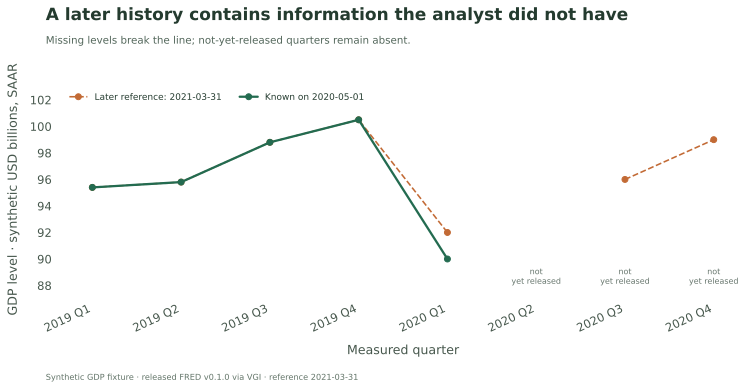

In [11]:
x = np.arange(len(levels))
fig, ax = plt.subplots(figsize=(10.8, 5.7))
ax.plot(
    x,
    levels.reference_usd_bn.astype(float),
    "o--",
    color="#C26A35",
    label="Later reference: 2021-03-31",
    linewidth=1.6,
)
ax.plot(
    x, levels.selected_usd_bn.astype(float), "o-", color="#236B50", label=f"Known on {AS_OF}", linewidth=2.3
)
for i, row in levels.iterrows():
    if row.selected_status != "numeric value":
        ax.text(
            i,
            0.035,
            row.selected_status.replace(" ", "\n", 1),
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="bottom",
            fontsize=8,
            color="#66756C",
        )
ax.set_xticks(x, levels.period, rotation=25, ha="right")
ax.set_ylabel("GDP level · synthetic USD billions, SAAR")
ax.set_xlabel("Measured quarter")
ax.margins(y=0.25)
ax.legend(loc="upper left", ncol=2, fontsize=9)
finish(
    fig,
    "A later history contains information the analyst did not have",
    "Missing levels break the line; not-yet-released quarters remain absent.",
    source,
    name=f"vintage-levels-{AS_OF}",
)

### Measure growth across adjacent calendar quarters

Now measure growth using adjacent calendar quarters, rather than adjacent non-NULL
rows. Because these toy levels share the same annual-rate convention, their ratio
gives a quarter-to-quarter percentage change: 100 × (level / prior-quarter level − 1).
This is not an annualized growth rate. A missing or unavailable quarter blocks both
its own growth rate and the next quarter's; SQL must not jump across that gap.

In [12]:
%%sql
CREATE TABLE growth AS
WITH adjacent AS (
    SELECT *, lag(selected_usd_bn) OVER (ORDER BY quarter) AS prior_selected,
        lag(reference_usd_bn) OVER (ORDER BY quarter) AS prior_reference
    FROM comparison
)
SELECT quarter, period,
    100.0 * (selected_usd_bn / nullif(prior_selected, 0) - 1) AS selected_qoq_pct,
    100.0 * (reference_usd_bn / nullif(prior_reference, 0) - 1) AS reference_qoq_pct
FROM adjacent;
SELECT period, round(selected_qoq_pct, 3) AS known_qoq_pct,
    round(reference_qoq_pct, 3) AS reference_qoq_pct,
    round(reference_qoq_pct - selected_qoq_pct, 3) AS later_revision_percentage_points
FROM growth ORDER BY quarter;

,period,known_qoq_pct,reference_qoq_pct,later_revision_percentage_points
0,2019 Q1,NaN,NaN,NaN
1,2019 Q2,0.419,0.419,0.00
2,2019 Q3,3.132,3.132,0.00
3,2019 Q4,1.721,1.721,0.00
4,2020 Q1,-10.448,-8.458,1.99
5,2020 Q2,NaN,NaN,NaN
6,2020 Q3,NaN,NaN,NaN
7,2020 Q4,NaN,3.125,NaN


In [13]:
%%sql rates <<
SELECT * FROM growth ORDER BY quarter;

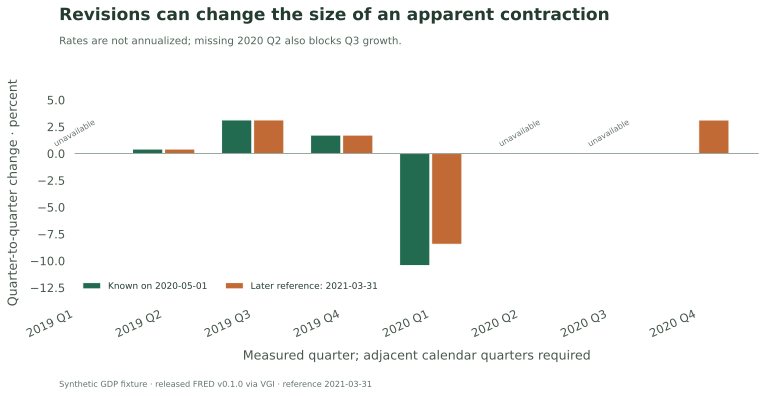

In [14]:
fig, ax = plt.subplots(figsize=(10.8, 5.8))
x = np.arange(len(rates))
ax.bar(x - 0.18, rates.selected_qoq_pct.astype(float), width=0.34, color="#236B50", label=f"Known on {AS_OF}")
ax.bar(
    x + 0.18,
    rates.reference_qoq_pct.astype(float),
    width=0.34,
    color="#C26A35",
    label="Later reference: 2021-03-31",
)
for i, row in rates.iterrows():
    if pd.isna(row.selected_qoq_pct) and pd.isna(row.reference_qoq_pct):
        ax.annotate(
            "unavailable",
            (i, 0),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            rotation=30,
            color="#66756C",
        )
ax.axhline(0, color="#819488", linewidth=0.8)
ax.set_xticks(x, rates.period, rotation=25, ha="right")
ax.set_ylabel("Quarter-to-quarter change · percent")
ax.set_xlabel("Measured quarter; adjacent calendar quarters required")
ax.legend(loc="lower left", ncol=2, fontsize=9)
ax.margins(y=0.23)
finish(
    fig,
    "Revisions can change the size of an apparent contraction",
    "Rates are not annualized; missing 2020 Q2 also blocks Q3 growth.",
    source,
    name=f"vintage-growth-{AS_OF}",
)

In [15]:
q1 = rates.loc[rates.period == "2020 Q1"].iloc[0]
if pd.notna(q1.selected_qoq_pct):
    delta = q1.reference_qoq_pct - q1.selected_qoq_pct
    prose(
        f"For synthetic **2020 Q1**, the selected vintage implies **{q1.selected_qoq_pct:.2f}%** "
        f"quarter-to-quarter growth; the fixed reference implies **{q1.reference_qoq_pct:.2f}%**. "
        f"The later revision changes the measured growth rate by **{delta:+.2f} percentage points**. "
        "The missing Q2 still prevents a Q3 growth estimate, even when Q3's level is known."
    )
else:
    prose(
        f"At {AS_OF}, a 2020 Q1 growth estimate is not available. "
        "The later reference's estimate uses information outside this selected knowledge date."
    )

For synthetic **2020 Q1**, the selected vintage implies **-10.45%** quarter-to-quarter growth; the fixed reference implies **-8.46%**. The later revision changes the measured growth rate by **+1.99 percentage points**. The missing Q2 still prevents a Q3 growth estimate, even when Q3's level is known.

### Check interval and missing-value invariants

Verify the temporal contract before drawing conclusions. A snapshot should exactly
match the full revision history filtered by its inclusive knowledge interval. These
checks also cover unique quarters, missing-value preservation, nonoverlapping versions,
calendar-aligned growth and identical measured windows.

In [16]:
%%sql checks <<
WITH expected AS (
    SELECT date, value, value_text FROM revision_history
    WHERE DATE '{{ AS_OF }}' BETWEEN realtime_start AND realtime_end
), differences AS (
    (SELECT date, value, value_text FROM selected_snapshot EXCEPT SELECT * FROM expected)
    UNION ALL
    (SELECT * FROM expected EXCEPT SELECT date, value, value_text FROM selected_snapshot)
), intervals AS (
    SELECT *, lead(realtime_start) OVER (PARTITION BY date ORDER BY realtime_start) AS next_start
    FROM revision_history
)
SELECT 'Selected snapshot equals interval lookup' AS invariant, count(*) = 0 AS passed FROM differences
UNION ALL SELECT 'Selected quarters are unique', count(*) = count(DISTINCT date) FROM selected_snapshot
UNION ALL SELECT 'Reference quarters are unique', count(*) = count(DISTINCT date) FROM reference_snapshot
UNION ALL SELECT 'Calendar retains all eight quarters', count(*) = 8 FROM comparison
UNION ALL SELECT 'Missing markers remain SQL NULL', bool_and((value_text = '.') = (value IS NULL)) FROM revision_history
UNION ALL SELECT 'Revisions have ordered inclusive intervals', bool_and(realtime_start <= realtime_end) FROM revision_history
UNION ALL SELECT 'Version intervals do not overlap', bool_and(next_start IS NULL OR realtime_end < next_start) FROM intervals
UNION ALL SELECT 'Snapshot knowledge bounds equal requested date',
    bool_and(realtime_start = DATE '{{ AS_OF }}' AND realtime_end = DATE '{{ AS_OF }}') FROM selected_snapshot
UNION ALL SELECT 'Fixed reference bounds are explicit',
    bool_and(realtime_start = DATE '2021-03-31' AND realtime_end = DATE '2021-03-31') FROM reference_snapshot
UNION ALL SELECT 'Missing quarter never bridged for growth', bool_and(reference_qoq_pct IS NULL)
    FROM growth WHERE quarter IN (DATE '2020-04-01', DATE '2020-07-01')
UNION ALL SELECT 'Metadata confirms quarterly level units',
    bool_and(frequency = 'Quarterly' AND units = 'Billions of US dollars') FROM series_info
UNION ALL SELECT 'Known values precede the reference cutoff',
    bool_and(realtime_start <= DATE '2021-03-31') FROM revision_history;

In [17]:
display(checks)
assert len(checks) == 12 and checks.passed.all()
requests = fixture.audit(AS_OF)
prose(
    f"All **{len(checks)} SQL invariants** pass. The HTTP audit confirms exactly "
    f"**{requests} local fixture requests** for the four materialized scans, including pagination; "
    "displaying tables and charts added no upstream calls."
)
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/vintage-audit.json").write_text(
    json.dumps(
        {
            "as_of": AS_OF,
            "requests": requests,
            "levels": levels.to_dict("records"),
            "growth": rates.to_dict("records"),
            "history": con.execute("SELECT * FROM revision_history ORDER BY date,realtime_start")
            .fetchdf()
            .to_dict("records"),
            "reference": con.execute("SELECT * FROM reference_snapshot ORDER BY date")
            .fetchdf()
            .to_dict("records"),
            "checks": checks.to_dict("records"),
        },
        indent=2,
        default=str,
    )
)

,invariant,passed
0,Selected snapshot equals interval lookup,True
1,Selected quarters are unique,True
2,Reference quarters are unique,True
3,Calendar retains all eight quarters,True
4,Missing markers remain SQL NULL,True
5,Revisions have ordered inclusive intervals,True
6,Version intervals do not overlap,True
7,Snapshot knowledge bounds equal requested date,True
8,Fixed reference bounds are explicit,True
9,Missing quarter never bridged for growth,True


All **12 SQL invariants** pass. The HTTP audit confirms exactly **9 local fixture requests** for the four materialized scans, including pagination; displaying tables and charts added no upstream calls.

11354

### Experiment: advance the available information

**Focused experiment.** Change AS_OF from 2020-05-01 to 2020-08-01 and run all in
a separate copy. Predict that Q1's selected level will incorporate later revisions,
while Q2 will become a reported missing observation. Compare the Q1 growth revision,
availability counts and two charts. The reference snapshot and complete revision
history must stay identical. This is a change in available information, not a
forecast test or a statement about official economic releases. Reset AS_OF to
2020-05-01 for the saved default. Exact runner commands are in README.md.

In [18]:
assert con.execute("SELECT name, persistent, storage FROM duckdb_secrets()").fetchall() == [
    ("fred_fixture", False, "memory")
]
con.execute("DROP SECRET fred_fixture")
assert con.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
session.close()
fixture.stop()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-fred](https://github.com/Query-farm/vgi-fred)
